## B5 · Exploring data with pandas

Summary statistics, counting categories, comparing groups, missing data, duplicates and quick plots.

In [474]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

### Describing the data

#### Calculating summary statistics

**B5.01**

`df['c'].mean(), .median(), .std(), .min(), .max(), .count()`

Methods such as `.mean()`, `.median()` and `.std()` allow us to summarise a column with a single number. They are useful for describing the centre and spread of a variable. Alternatively, `.describe()` gives all of them at once.

Each statistic skips missing values (`NaN`), so `count` can be smaller than the number of rows.

In [475]:
col_m = df_penguins["body_mass_g"]
print(f"mean   = {col_m.mean():.1f} g")

mean   = 4201.8 g


In [476]:
print(f"median = {col_m.median():.1f} g")

median = 4050.0 g


In [477]:
print(f"std    = {col_m.std():.1f} g")

std    = 802.0 g


In [478]:
print(f"min    = {col_m.min():.0f} g, max = {col_m.max():.0f} g")

min    = 2700 g, max = 6300 g


In [479]:
print(f"count : {col_m.count()} of {len(col_m)} (missing values are skipped)")

count : 342 of 344 (missing values are skipped)


*See also:* Describing the whole table (B5) · Summarising an array (A4) · Choosing the standard deviation formula with `ddof` (A4) · How statistics treat `NaN` (B5) · Grouping and summarising with `groupby` (B9) · Measuring skewness and kurtosis (B5)

#### Finding quartiles

**B5.02**

`df['col'].quantile(q)`

The `.quantile()` method allows us to find the value below which a given fraction of the data falls. It is useful for quartiles and for box plot summaries. Alternatively, `np.percentile` uses percentages (25, 50, 75) rather than fractions.

In [480]:
col_m = df_penguins["body_mass_g"]
col_m.quantile(0.25)

np.float64(3550.0)

In [481]:
col_m.quantile([0.25, 0.5, 0.75])

0.25    3550.0
0.50    4050.0
0.75    4750.0
Name: body_mass_g, dtype: float64

Note: `describe()` already includes the quartiles (the 25%, 50% and 75% rows).

*See also:* Finding the median and percentiles (A4) · Drawing a box plot with `boxplot` (C3) · Binning numbers into equal-sized groups with `qcut` (B4) · Describing the whole table (B5) · Finding outliers with the IQR rule (B5)

#### Finding outliers with the IQR rule

**B5.29**

`q1, q3 = s.quantile([0.25, 0.75]); mask = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)`

***(non-examinable)***

If we want to flag unusual values, then we can mark any value more than 1.5 times the interquartile range beyond the quartiles as an outlier. It is useful for deciding which points a box plot will draw individually, and for checking them before they affect a mean. Alternatively, `sns.boxplot` shows the same points without calculating them.

In [482]:
col_m = df_penguins["body_mass_g"]
q1, q3 = col_m.quantile([0.25, 0.75])
iqr = q3 - q1
mask_outlier = (col_m < q1 - 1.5 * iqr) | (col_m > q3 + 1.5 * iqr)
print(f"fences: {q1 - 1.5 * iqr:.0f} g to {q3 + 1.5 * iqr:.0f} g")

fences: 1750 g to 6550 g


In [483]:
print(f"outliers: {mask_outlier.sum()}")

outliers: 0


In [484]:
df_penguins[mask_outlier]                   # the rows themselves, if there are any

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


*See also:* Finding quartiles (B5) · Filtering rows with a mask (B3) · Combining conditions with `&` and `|` (B3) · Describing the whole table (B5)

#### Describing the whole table

**B5.03**

`df.describe()`

The `.describe()` method allows us to produce count, mean, std, min, quartiles and max for every numeric column. It is useful as a first look at a dataset. Alternatively, call individual methods for single statistics.

In [485]:
df_penguins.describe().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


*See also:* Calculating summary statistics (B5) · Describing text columns too (B5) · Finding the row of the largest value (B5) · Plotting a histogram with pandas (B5) · Correlating all numeric columns (B5)

#### Correlating all numeric columns

**B5.30**

`df.corr(numeric_only=True)`

***(non-examinable)***

The `.corr()` method allows us to calculate the correlation between every pair of numeric columns in one table. It is useful for spotting which variables move together before plotting or fitting a model. Alternatively, `sns.heatmap` draws the same table as colours.

In [486]:
df_penguins.corr(numeric_only=True).round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.60
bill_depth_mm,-0.24,1.00,-0.58,-0.47
flipper_length_mm,0.66,-0.58,1.00,0.87
body_mass_g,0.60,-0.47,0.87,1.00


One pair of columns uses `Series.corr`:

In [487]:
df_penguins["flipper_length_mm"].corr(df_penguins["body_mass_g"])

np.float64(0.8712017673060116)

*See also:* Checking the correlation first (D5) · Drawing a scatter plot with `scatterplot` (C3) · Plotting every pair of variables (C3) · Describing the whole table (B5)

#### Ranking values

**B5.32**

`s.rank(), s.rank(ascending=False, method='min')`

***(non-examinable)***

The `.rank()` method allows us to replace each value with its position in the sorted order, with 1 for the smallest. It is useful for comparing rows by order rather than size, and for breaking ties in a stated way. Alternatively, `sort_values` orders the rows but does not record the rank.

In [488]:
col_m = df_penguins["body_mass_g"].head(5)
col_m.rank().tolist()                                    # ties share the average rank

[3.0, 4.0, 1.0, nan, 2.0]

In [489]:
col_m.rank(ascending=False, method='min').tolist()      # 1 = heaviest, ties share the lowest rank

[2.0, 1.0, 4.0, nan, 3.0]

In [490]:
df_penguins["mass_rank"] = df_penguins["body_mass_g"].rank(ascending=False, method="min")
df_penguins.nsmallest(3, "mass_rank")[["species", "body_mass_g", "mass_rank"]]

,species,body_mass_g,mass_rank
237,Gentoo,6300.0,1.0
253,Gentoo,6050.0,2.0
297,Gentoo,6000.0,3.0


*See also:* Finding the row of the largest value (B5) · Sorting by a column (B3) · Adding a calculated column (B4)

#### Finding the row of the largest value

**B5.04**

`idx = df['c'].idxmax(); df.loc[idx]`

The `.idxmax()` method allows us to find the *label* of the row with the largest value, which we can then look up with `loc`. It is useful when the whole record of the maximum is needed, not only its value. Alternatively, `df.sort_values(...).head(1)` returns the top row.

In [491]:
idx = df_penguins["body_mass_g"].idxmax()
print(f"label of heaviest penguin: {idx}")

label of heaviest penguin: 237


In [492]:
df_penguins.loc[idx]

species              Gentoo
island               Biscoe
bill_length_mm         49.2
bill_depth_mm          15.2
flipper_length_mm     221.0
body_mass_g          6300.0
sex                    Male
mass_rank               1.0
Name: 237, dtype: object

`idxmin()` finds the smallest:

In [493]:
df_penguins.loc[df_penguins["body_mass_g"].idxmin()]

species              Chinstrap
island                   Dream
bill_length_mm            46.9
bill_depth_mm             16.6
flipper_length_mm        192.0
body_mass_g             2700.0
sex                     Female
mass_rank                342.0
Name: 190, dtype: object

*See also:* Sorting by a column (B3) · Selecting one row by label (B3) · Sorting in descending order (B3) · Summing and accumulating values (B5) · Filtering rows with a mask (B3) · Ranking values (B5)

#### Summing and accumulating values

**B5.05**

`s.sum(), s.cumsum()`

The `.sum()` and `.cumsum()` methods allow us to total a column or build a running total. They are useful for totals and cumulative probabilities. Alternatively, `np.sum` and `np.cumsum` work on arrays.

In [494]:
# display the example data
s = pd.Series([1, 2, 3, 4])
s

0    1
1    2
2    3
3    4
dtype: int64

In [495]:
print(f"sum   : {s.sum()}")

sum   : 10


In [496]:
print(f"cumsum: {s.cumsum().tolist()}")

cumsum: [1, 3, 6, 10]


*See also:* Rounding, accumulating and taking absolute values (A4) · Calculating cumulative sums (B4) · Turning counts into probabilities (B4) · Calculating variance, mode and standard error (B5) · Calculating changes between rows (B8)

#### Calculating variance, mode and standard error

**B5.06**

`s.var(), s.mode(), s.sem()`

***(non-examinable)***

The `.var()`, `.mode()` and `.sem()` methods allow us to measure spread, the most common value and the precision of the mean. They are useful for confidence intervals and categorical data. Alternatively, `.std() ** 2` gives the variance.

In [497]:
col_m = df_penguins["body_mass_g"]
print(f"variance      : {round(col_m.var(), 1)}")

variance      : 643131.1


In [498]:
print(f"standard error: {round(col_m.sem(), 1)}")

standard error: 43.4


In [499]:
print(f'most common species: {df_penguins["species"].mode()[0]}')

most common species: Adelie


*See also:* Calculating summary statistics (B5) · Finding quartiles (B5) · Choosing the standard deviation formula with `ddof` (A4)

#### Measuring skewness and kurtosis

**B5.31**

`s.skew(), s.kurt()`

***(non-examinable)***

The `.skew()` and `.kurt()` methods allow us to measure how lopsided a distribution is and how heavy its tails are. They are useful for judging whether a column is close to symmetric before using a mean. Alternatively, a histogram shows the shape directly.

In [500]:
col_m = df_penguins["body_mass_g"]
print(f"skewness: {round(col_m.skew(), 2)}")     # 0 for a symmetric distribution

skewness: 0.47


In [501]:
print(f"kurtosis: {round(col_m.kurt(), 2)}")     # 0 for a normal distribution

kurtosis: -0.72


*See also:* Calculating summary statistics (B5) · Comparing a histogram with a normal curve (D2)

#### Listing the unique values

**B5.07**

`s.unique(), s.nunique()`

***(non-examinable)***

The `.unique()` and `.nunique()` methods allow us to list the different values in a column and count them. They are useful for checking categories and spotting typos. Alternatively, `value_counts()` also shows how often each occurs.

In [502]:
df_penguins['island'].unique()

array(['Torgersen', 'Biscoe', 'Dream'], dtype=object)

In [503]:
print(f'number of islands: {df_penguins["island"].nunique()}')

number of islands: 3


*See also:* How statistics treat `NaN` (B5) · Finding and dropping duplicates (B5)

#### Describing text columns too

**B5.08**

`df.describe(include='all')`

***(non-examinable)***

The `include='all'` option allows us to summarise text columns (count, unique, most common) as well as numeric ones. It is useful for a first look at mixed data. Alternatively, `df.select_dtypes('object').describe()` shows only the text columns.

In [504]:
df_penguins.describe(include="all")

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,mass_rank
count,344,344,342.000000,342.000000,342.000000,342.000000,333,342.000000
unique,3,3,NaN,NaN,NaN,NaN,2,NaN
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,Male,NaN
freq,152,168,NaN,NaN,NaN,NaN,168,NaN
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN,169.274854
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN,98.503914
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN,1.000000
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN,86.000000
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN,167.000000
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN,254.000000


*See also:* Describing the whole table (B5) · Calculating summary statistics (B5) · Checking the column types (B1)

### Counting categories

#### Counting each category

**B5.09**

`df['c'].value_counts()`

The `.value_counts()` method allows us to count how many rows fall in each category. It is useful for sample sizes in each group. Alternatively, `groupby(...).size()` gives the same counts and `sns.countplot` draws them.

In [505]:
df_penguins["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

*See also:* Keeping the category order when counting (B5) · Turning counts into a table (B5) · Counting categories with `countplot` (C3) · Counting two categories together (B5)

#### Keeping the category order when counting

**B5.10**

`value_counts(sort=False)`

The `sort=False` option allows us to keep categories in their original order instead of largest first. It is useful for categories that have a natural order. Alternatively, `.sort_index()` after counting sorts by category.

In [506]:
# display the example data
col_rolls = pd.Series([3, 1, 6, 3, 3, 2, 6, 1, 3])
col_rolls

0    3
1    1
2    6
3    3
4    3
5    2
6    6
7    1
8    3
dtype: int64

In [507]:
col_rolls.value_counts()               # most common first

3    4
1    2
6    2
2    1
Name: count, dtype: int64

In [508]:
col_rolls.value_counts().sort_index()  # in order of the value

1    2
2    1
3    4
6    2
Name: count, dtype: int64

*See also:* Counting each category (B5) · Sorting by the index (B2)

#### Turning counts into a table

**B5.11**

`.value_counts().to_frame().reset_index()`

Chaining `.to_frame().reset_index()` allows us to turn the result of `value_counts` into an ordinary DataFrame. It is useful for plotting with seaborn or merging with other tables. Alternatively, `rename_axis(...).reset_index(name=...)` sets clearer column names.

In [509]:
df_counts = df_penguins["species"].value_counts().to_frame().reset_index()
df_counts.columns.tolist()

['species', 'count']

In [510]:
# display example data
df_counts

,species,count
0,Adelie,152
1,Gentoo,124
2,Chinstrap,68


*See also:* Naming the index and column axes (B2) · Counting each category (B5) · Moving the index back into a column (B2) · Drawing a bar plot of values (C3)

#### Counting proportions instead of numbers

**B5.12**

`value_counts(normalize=True)`

***(non-examinable)***

The `normalize=True` option allows us to get proportions that add up to 1 instead of counts. It is useful for probabilities and for comparing groups of different sizes. Alternatively, divide the counts by `len(df)`.

In [511]:
df_penguins['species'].value_counts(normalize=True).round(3)

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64

In [512]:
df_penguins['species'].value_counts() / len(df_penguins)   # the same, by hand

species
Adelie       0.441860
Gentoo       0.360465
Chinstrap    0.197674
Name: count, dtype: float64

*See also:* Turning counts into probabilities (B4) · Counting each category (B5)

#### Counting two categories together

**B5.13**

`pd.crosstab(df['a'], df['b'])`

***(non-examinable)***

The `pd.crosstab()` function allows us to count how many rows fall in each combination of two categories. It is useful for questions about two categories at once. Alternatively, `groupby([a, b]).size()` gives the same numbers in long form.

In [513]:
pd.crosstab(df_penguins["species"], df_penguins["island"])

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


*See also:* Counting each category (B5) · Summarising into a grid with `pivot_table` (B9) · Counting proportions instead of numbers (B5)

### Group comparisons

#### Comparing groups with masks

**B5.14**

`mask per group, then a statistic`

If we want a statistic for each of several groups, then we can build one mask per group and calculate the statistic on each. It is useful for comparing, say, two species of penguin. Alternatively, `groupby` does this for every group in one line (see the non-examinable GroupBy sheet).

In [514]:
mask_adelie = df_penguins["species"] == "Adelie"
mask_gentoo = df_penguins["species"] == "Gentoo"

mean_adelie = df_penguins.loc[mask_adelie, "body_mass_g"].mean()
mean_gentoo = df_penguins.loc[mask_gentoo, "body_mass_g"].mean()
print(f"Adelie mean mass: {mean_adelie:.0f} g")

Adelie mean mass: 3701 g


In [515]:
print(f"Gentoo mean mass: {mean_gentoo:.0f} g")

Gentoo mean mass: 5076 g


*See also:* Filtering rows with a mask (B3) · Combining conditions with `&` and `|` (B3)

#### Building a summary table

**B5.15**

`pd.DataFrame(d).set_index('col').round(n)`

If we have several group statistics, then we can put them in a small DataFrame to present them side by side. It is useful for tables in a report. Alternatively, `groupby(...).agg([...])` produces such a table automatically.

In [516]:
col_adelie = df_penguins.loc[df_penguins["species"] == "Adelie", "body_mass_g"]
col_gentoo = df_penguins.loc[df_penguins["species"] == "Gentoo", "body_mass_g"]

df_table = pd.DataFrame({
    "statistic": ["mean", "std", "n"],
    "Adelie": [col_adelie.mean(), col_adelie.std(), col_adelie.count()],
    "Gentoo": [col_gentoo.mean(), col_gentoo.std(), col_gentoo.count()],
}).set_index("statistic").round(1)
df_table

,Adelie,Gentoo
statistic,,
mean,3700.7,5076.0
std,458.6,504.1
n,151.0,123.0


*See also:* Grouping and summarising with `groupby` (B9) · Comparing groups with masks (B5) · Turning a dictionary into a DataFrame (A3) · Saving to a CSV file (B1) · Saving a grouped table (B5)

#### Saving a grouped table

**B5.33**

`df.groupby('group')['col'].agg(funcs).reset_index().to_csv("out.csv", index=False)`

***(non-examinable)***

If we have a grouped summary, then we can write it to a file with `to_csv` once the group labels have been moved back into a column. It is useful for passing a table of group statistics to a report or another program. Alternatively, `to_pickle` keeps the exact types.

In [517]:
df_summary = (
    df_penguins.groupby("species")["body_mass_g"]
    .agg(["mean", "std", "count"])
    .round(1)
    .reset_index()
)
df_summary.to_csv("species_summary.csv", index=False)

In [518]:
pd.read_csv("species_summary.csv")                      # read it back to check

,species,mean,std,count
0,Adelie,3700.7,458.6,151
1,Chinstrap,3733.1,384.3,68
2,Gentoo,5076.0,504.1,123


*See also:* Saving to a CSV file (B1) · Returning a flat table from groupby (B9) · Building a summary table (B5) · Calculating several statistics per group (B9)

### Missing data and duplicates

#### Counting missing values

**B5.16**

`df.isna().sum()`

The `.isna().sum()` combination allows us to count the missing values in each column. It is useful as the first check on any dataset, because missing values affect statistics and fits. Alternatively, `df.info()` shows non-null counts instead.

`isna()` gives `True` where a value is missing (`NaN`); summing counts the `True`s.

In [519]:
df_penguins.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
mass_rank             2
dtype: int64

*See also:* Summarising a DataFrame with `info()` (B1) · Comparing `count()` with `len()` (B5) · Showing the rows with missing values (B5) · Removing rows with missing values (B5) · Filling missing values (B5)

#### Comparing `count()` with `len()`

**B5.17**

`df.info(), df['c'].count() vs len(df)`

Comparing `count()` with `len()` allows us to see how many values are missing in a column. It is useful because `count()` skips missing values but `len()` does not. Alternatively, `isna().sum()` gives the same number directly.

In [520]:
n_rows = len(df_penguins)
n_present = df_penguins["bill_length_mm"].count()
print(f"rows                      : {n_rows}")

rows                      : 344


In [521]:
print(f"non-missing bill_length_mm: {n_present}")

non-missing bill_length_mm: 342


In [522]:
print(f"missing bill_length_mm    : {n_rows - n_present}")

missing bill_length_mm    : 2


*See also:* Summarising a DataFrame with `info()` (B1)

#### Showing the rows with missing values

**B5.18**

`df[df['bill_length_mm'].isna()]`

Using `isna()` as a mask allows us to look at exactly which rows have missing values. It is useful for deciding whether to drop, fill or investigate them. Alternatively, `notna()` gives the complete rows instead.

A mask built with `isna()` selects the incomplete rows (here two penguins have no measurements at all):

In [523]:
df_penguins[df_penguins["bill_length_mm"].isna()]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,mass_rank
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,NaN


*See also:* Counting missing values (B5) · Filtering rows with a mask (B3) · Removing rows with missing values (B5)

#### Removing rows with missing values

**B5.19**

`df.dropna(), df.dropna(subset=['bill_length_mm'])`

The `.dropna()` method allows us to remove rows that contain missing values. It is useful before calculations that cannot handle `NaN`. Alternatively, `fillna()` replaces missing values rather than removing the rows.

`dropna()` drops a row if **any** column is missing; `subset=` restricts the check to the named columns.

In [524]:
print(f"all rows                           : {len(df_penguins)}")

all rows                           : 344


In [525]:
print(f"dropna()                           : {len(df_penguins.dropna())}")

dropna()                           : 333


In [526]:
print(f"dropna(subset=['bill_length_mm'])  : {len(df_penguins.dropna(subset=['bill_length_mm']))}")

dropna(subset=['bill_length_mm'])  : 342


Watch out: dropping rows changes every statistic that follows, so check how many rows were removed (`len(df)` before and after).

*See also:* Filling missing values (B5) · Handling `NaN` before `linregress` (B5)

#### Filling missing values

**B5.20**

`df['c'].fillna(0), df['c'].fillna(df['c'].mean())`

The `.fillna()` method allows us to replace missing values with a chosen value, such as 0 or the mean. It is useful when a missing value genuinely means zero, or when a complete column is needed. Alternatively, `dropna()` removes the incomplete rows instead.

Watch out: Filling invents data. Fill values only when this is justified, and state what was done.

In [527]:
col_mass = df_penguins["body_mass_g"]
col_filled = col_mass.fillna(col_mass.mean())
print(f"missing before: {col_mass.isna().sum()}   after: {col_filled.isna().sum()}")

missing before: 2   after: 0


In [528]:
print(f"mean before: {col_mass.mean():.2f}   after: {col_filled.mean():.2f}")   # unchanged

mean before: 4201.75   after: 4201.75


*See also:* Removing rows with missing values (B5) · Filling reindexed labels that are missing (B2) · Counting missing values (B5) · Adding a group statistic to every row (B9)

#### How statistics treat `NaN`

**B5.21**

`s.mean() skips NaN;  value_counts(dropna=False)`

Knowing that pandas statistics skip `NaN` by default allows us to interpret results correctly. It is useful when a column has missing values, because the count behind a mean may be smaller than the table length. Alternatively, `value_counts(dropna=False)` shows missing values as their own category.

In [529]:
# display the example data
col_island = pd.Series(["Dream", "Biscoe", None, "Dream", None])
col_island

0     Dream
1    Biscoe
2      None
3     Dream
4      None
dtype: object

In [530]:
# display example data
col_island                                  # two values are missing

0     Dream
1    Biscoe
2      None
3     Dream
4      None
dtype: object

In [531]:
col_island.value_counts()                   # missing values are left out

Dream     2
Biscoe    1
Name: count, dtype: int64

In [532]:
col_island.value_counts(dropna=False)       # now they are counted too

Dream     2
None      2
Biscoe    1
Name: count, dtype: int64

*See also:* Counting missing values (B5) · Counting each category (B5)

#### Handling `NaN` before `linregress`

**B5.22**

`stats.linregress with NaN`

Dropping missing values before calling `linregress` allows us to avoid `nan` results. It is useful because, unlike pandas, SciPy does not skip missing values. Alternatively, `df.dropna(subset=[...])` keeps the other columns intact.

Watch out: `linregress` returns `nan` if any value is missing, so rows with missing values must be dropped first.

In [533]:
df_sub = df_penguins[["flipper_length_mm", "body_mass_g"]]
print(f'with NaN   : {stats.linregress(df_sub["flipper_length_mm"], df_sub["body_mass_g"]).slope}')

with NaN   : nan


In [534]:
df_clean = df_sub.dropna()
print(f'after drop : {round(stats.linregress(df_clean["flipper_length_mm"], df_clean["body_mass_g"]).slope, 2)}')

after drop : 49.69


*See also:* Removing rows with missing values (B5) · Fitting a line (D5) · Checking the correlation first (D5)

#### Finding and dropping duplicates

**B5.23**

`df.duplicated(), df.drop_duplicates()`

The `.duplicated()` and `.drop_duplicates()` methods allow us to detect and remove repeated rows. They are useful for data entered twice. Alternatively, `subset=` limits the check to key columns such as an ID.

In [535]:
# display the example data
df = pd.DataFrame({"id": [1, 2, 2, 3], "x": ["a", "b", "b", "c"]})
df

,id,x
0,1,a
1,2,b
2,2,b
3,3,c


In [536]:
df.duplicated().tolist()          # True marks a repeat of an earlier row

[False, False, True, False]

In [537]:
df.drop_duplicates()

,id,x
0,1,a
1,2,b
3,3,c


*See also:* Removing rows with missing values (B5) · Listing the unique values (B5)

### Quick plots

#### Plotting a scatter with pandas

**B5.24**

`df.plot.scatter(x='col_1', y='col_2')`

The `df.plot.scatter()` method allows us to draw a scatter plot straight from a DataFrame. It is useful for a quick look at the relationship between two columns. Alternatively, `sns.scatterplot` or `plt.scatter` give more control.

In [538]:
# display the example data
df_penguins[["flipper_length_mm", "body_mass_g"]].head()

,flipper_length_mm,body_mass_g
0,181.0,3750.0
1,186.0,3800.0
2,195.0,3250.0
3,NaN,NaN
4,193.0,3450.0


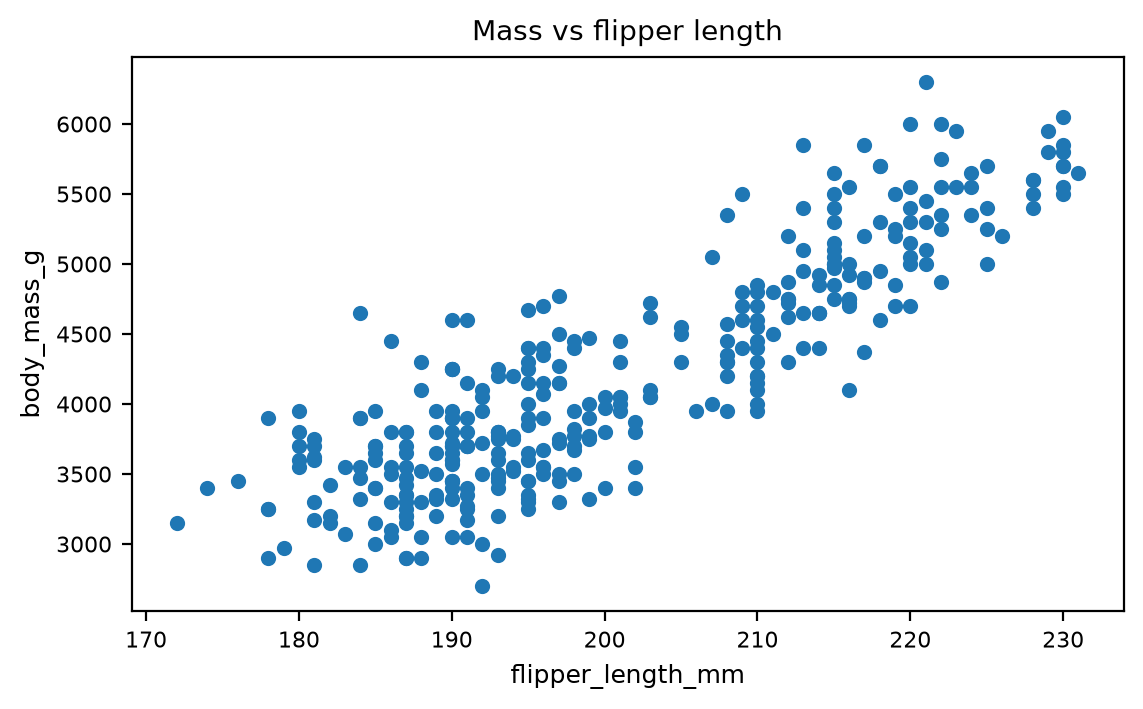

In [539]:
df_penguins.plot.scatter(x="flipper_length_mm", y="body_mass_g", title="Mass vs flipper length");

*See also:* Drawing a scatter plot (C2) · Drawing a scatter plot with `scatterplot` (C3) · Checking the correlation first (D5)

#### Plotting a histogram with pandas

**B5.25**

`df['col'].plot.hist(bins=n)`

The `.plot.hist()` method allows us to draw the distribution of a column. It is useful for checking shape and outliers. Alternatively, `sns.histplot` and `plt.hist` do the same.

In [540]:
# display the example data
df_penguins["body_mass_g"].head()

0    3750.0
1    3800.0
2    3250.0
3       NaN
4    3450.0
Name: body_mass_g, dtype: float64

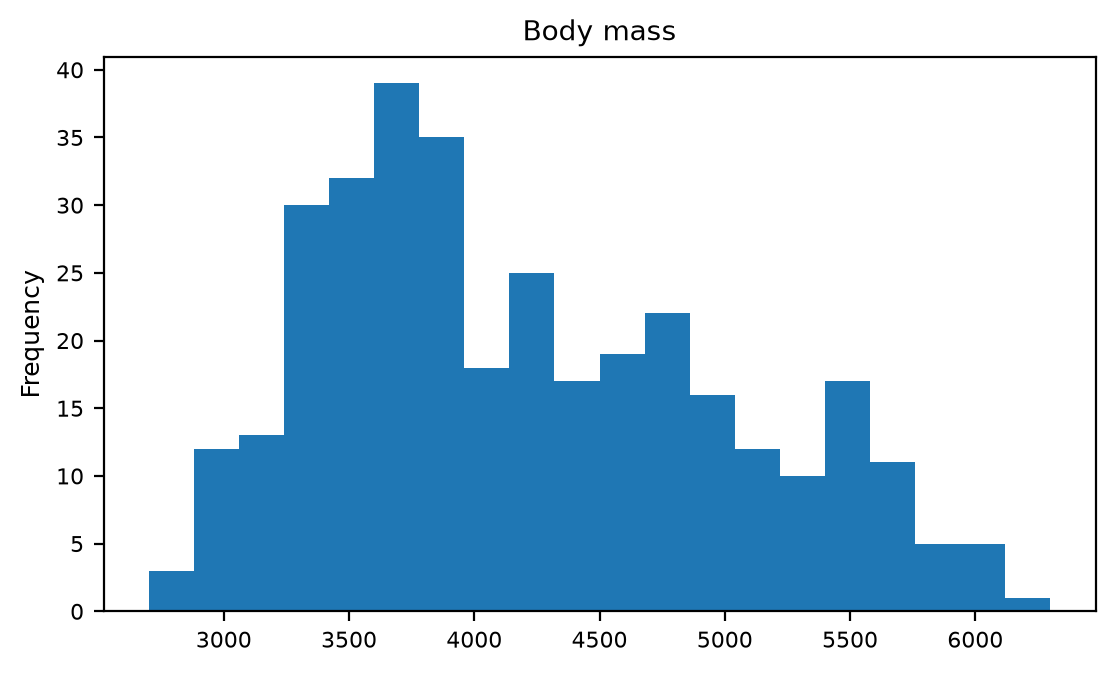

In [541]:
df_penguins["body_mass_g"].plot.hist(bins=20, title="Body mass");

*See also:* Drawing a histogram (C2) · Drawing a histogram with `histplot` (C3)

#### Plotting a box plot with pandas

**B5.26**

`df.plot.box(), df.boxplot(column='col', by='group')`

The `df.boxplot(column=, by=)` method allows us to compare the spread of a column across groups. It is useful for spotting differences and outliers between groups. Alternatively, `sns.boxplot` draws grouped boxes with more styling options.

In [542]:
# display the example data
df_penguins[["species", "body_mass_g"]].head()

,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0
3,Adelie,NaN
4,Adelie,3450.0


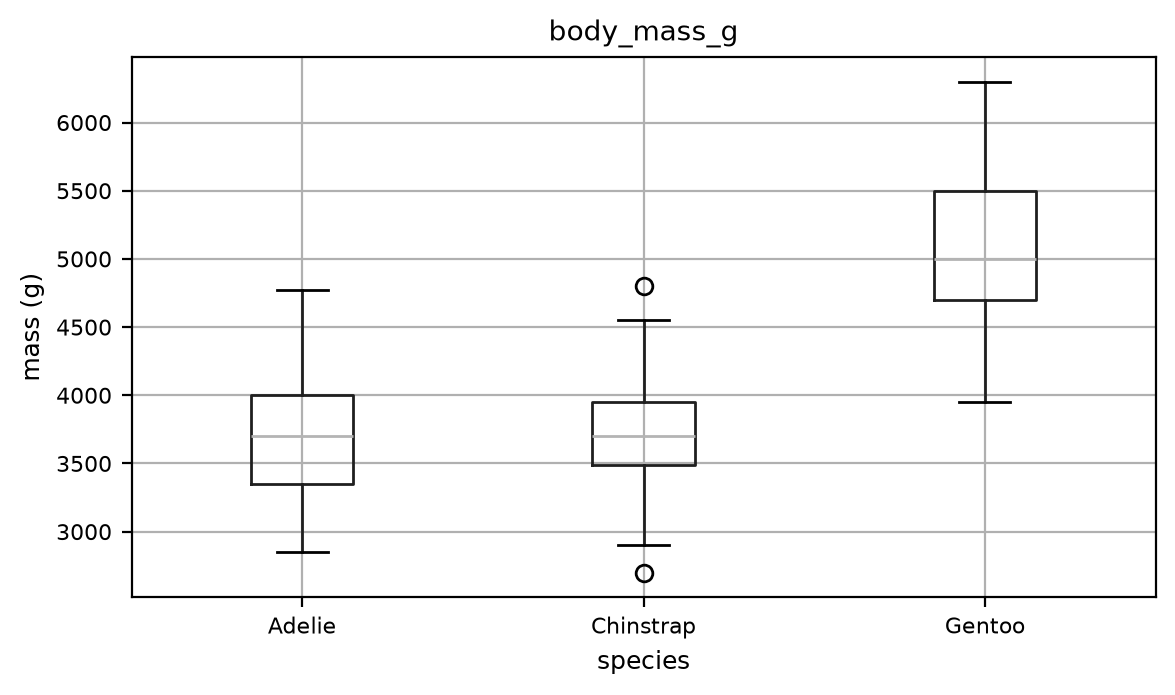

In [543]:
df_penguins.boxplot(column="body_mass_g", by="species")
plt.suptitle("")
plt.ylabel("mass (g)");

*See also:* Drawing a box plot with `boxplot` (C3) · Drawing several box plots (C2) · Using other pandas plot kinds (B5)

#### Using other pandas plot kinds

**B5.27**

`df.plot.line() .bar() .barh() .kde() .area() .pie() .hexbin()`

The `.plot.<kind>()` family allows us to draw bar, line, area, pie and density plots from pandas objects. They are useful for a quick look without importing seaborn. Alternatively, `df.plot(kind="bar")` is the same thing.

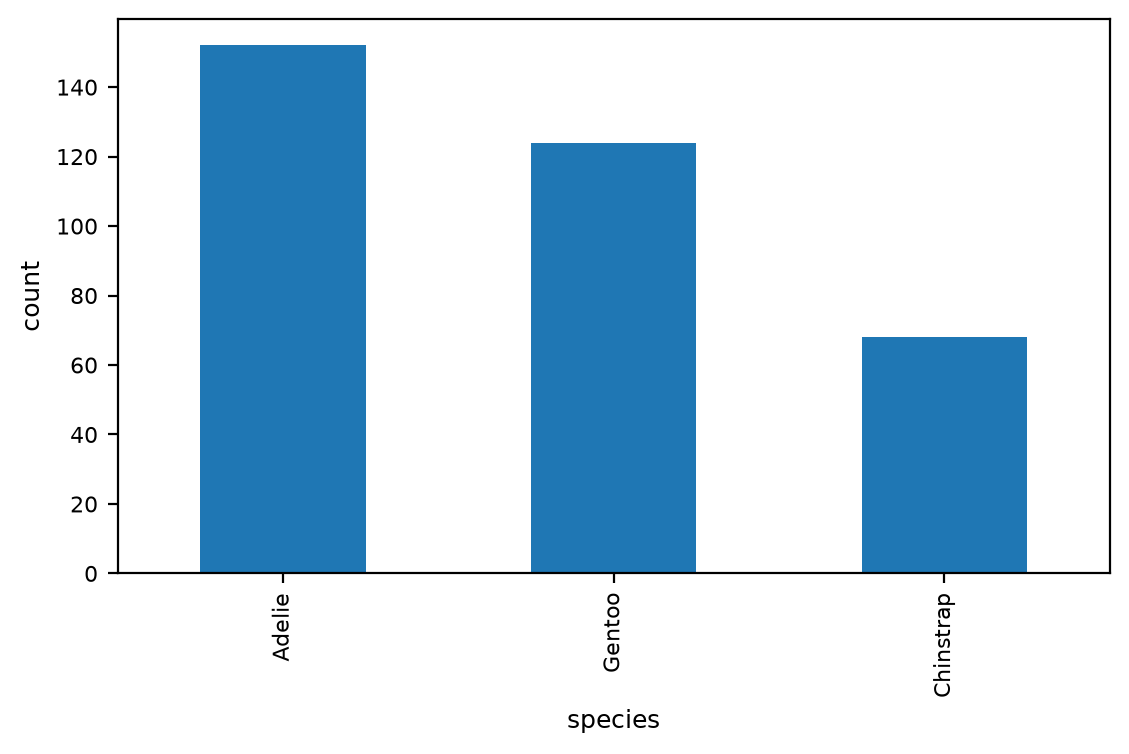

In [544]:
df_penguins["species"].value_counts().plot.bar(ylabel="count");

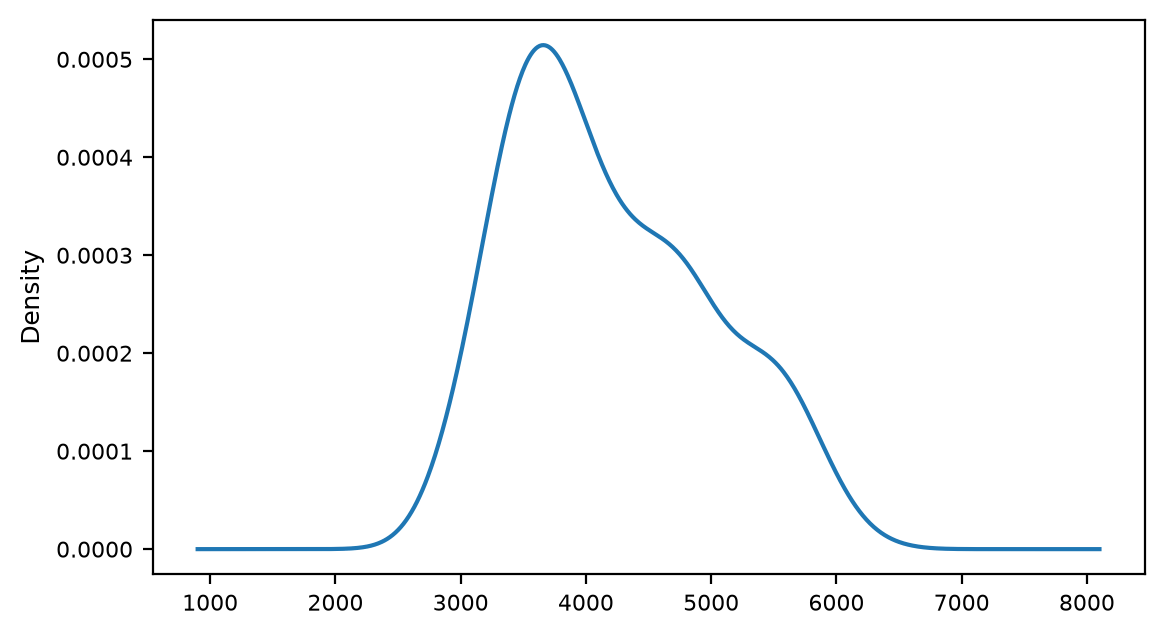

In [545]:
df_penguins["body_mass_g"].plot.kde();

*See also:* Drawing a bar chart (C2) · Drawing a pie chart (C2)

### Method

#### Following an exploration checklist

**B5.28**

`load → shape → missing → stats → plots → compare → interpret`

A fixed checklist allows us to explore any new dataset in a sensible order, which suits open-ended tasks where the starting point is unclear.

1. Load and look: `shape`, `head()`, `dtypes`
2. Missing values: `isna().sum()`
3. Summary statistics: `describe()`
4. Distributions: histograms and box plots
5. Relationships: scatter plots
6. Compare groups: masks (or `hue=` in seaborn)
7. Write 5–10 lines of interpretation

In [546]:
print(f"shape: {df_penguins.shape}")

shape: (344, 8)


In [547]:
print(f"missing values: {df_penguins.isna().sum().sum()}")

missing values: 21


In [548]:
df_penguins.describe().loc[["mean", "std"]].round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,mass_rank
mean,43.9,17.2,200.9,4201.8,169.3
std,5.5,2.0,14.1,802.0,98.5


*See also:* Checking the size of a DataFrame (B1) · Counting missing values (B5) · Describing the whole table (B5) · Plotting every pair of variables (C3) · Grouping and summarising with `groupby` (B9) · Plotting a histogram with pandas (B5) · Some principles for scientific data analysis (D6)